In [1]:
from fipy import (CellVariable, FaceVariable, Grid1D, DiffusionTerm, PowerLawConvectionTerm, ImplicitSourceTerm, TransientTerm, Viewer)
import numpy as np
import matplotlib.pyplot as plt

L, nx = 1.0, 100
dx = L / nx
max_sweeps, coupling_tolerance = 100, 1e-8

L_ref, T_ref, n_ref, V_ref, Vapp = 1e-8, 300.0, 1e28, 2.0, 1.0
kB, q = 1.380649e-23, 1.602176634e-19
a_hop, f_esc, Ea_eV = 3.2e-10, 1e12, 0.85

Ea = Ea_eV * q
D0 = 0.5 * a_hop**2 * f_esc

rho, Cp, k_ref = 8200.0, 26.0, 58.0
alpha_ref = k_ref / (rho * Cp)
t_ref = L_ref**2 / alpha_ref

ion_ratio = D0 / alpha_ref
E_ref, v_ref = V_ref / L_ref, alpha_ref / L_ref   # v_ref consistent with t_ref = L_ref**2 / alpha_ref
Gamma_a = Ea / (kB * T_ref)
chi_E = q * a_hop * E_ref / (2.0 * kB * T_ref)

T_op, T0_room = 300.0, 293.0
theta_op, theta_room = T_op / T_ref, T0_room / T_ref

params = {"L_ref": L_ref, "T_ref": T_ref, "n_ref": n_ref, "V_ref": V_ref, "D0": D0, "alpha_ref": alpha_ref, "ion_ratio": ion_ratio, "t_ref": t_ref, "E_ref": E_ref, "v_ref": v_ref, "Gamma_a": Gamma_a, "chi_E": chi_E, "theta_op": theta_op, "theta_room": theta_room}
for name, value in params.items():
    print(f"{name:<10} = {value:.4e}")

L_ref      = 1.0000e-08
T_ref      = 3.0000e+02
n_ref      = 1.0000e+28
V_ref      = 2.0000e+00
D0         = 5.1200e-08
alpha_ref  = 2.7205e-04
ion_ratio  = 1.8820e-04
t_ref      = 3.6759e-13
E_ref      = 2.0000e+08
v_ref      = 2.7205e+04
Gamma_a    = 3.2879e+01
chi_E      = 1.2378e+00
theta_op   = 1.0000e+00
theta_room = 9.7667e-01


In [2]:
alpha_ratio = alpha_ref / alpha_ref   

lam_th = 0.1
Lambda_th = lam_th * T_ref

T0_room = 293.0
theta_room = T0_room / T_ref

def S_hat_of_theta(theta_value):
    return -Gamma_a / theta_value**2

def D_hat_of_theta(theta_value):
    return ion_ratio * np.exp(-Gamma_a / theta_value)     

def v_hat_of_theta_E(theta_value, E_hat_value):
    return ion_ratio * ((2.0 * L_ref / a_hop) * np.exp(-Gamma_a / theta_value) * np.sinh(chi_E * E_hat_value / theta_value))   

def nD_cm3_of_N(N_value):
    return N_value * n_ref * 1.0e-6

sigma_ref = 1.0e5          
nD_ref_cm3 = 1.0e22        
T0_PF = 293.0              

Gamma_el = sigma_ref * E_ref**2 * t_ref / (rho * Cp * T_ref)

def sigma0_of_nD(nD_cm3):
    return np.interp(nD_cm3, [1.0e16, 1.0e22], [1.0, 1.0e5])

_nD_pts_cm3 = np.array([1.0e16, 1.0e20, 5.0e21, 1.0e22])
_Eac_pts_eV = np.array([0.20, 0.10, 0.00, -0.006])

def Eac_of_nD(nD_cm3):
    return np.interp(nD_cm3, _nD_pts_cm3, _Eac_pts_eV)

kB_eV = 8.617333262e-5       

def Eac_hat_of_nD(nD_cm3):
    Eac_eV = Eac_of_nD(nD_cm3)
    return Eac_eV / (kB_eV * T0_PF)

alpha_PF = 5.48e-4
beta_PF  = -5.70

def sigma_PF_hat(E_hat_value, theta_value):
    E_Vm = np.abs(E_hat_value) * E_ref
    expo = (theta_room / theta_value) * (alpha_PF * np.sqrt(E_Vm) + beta_PF)
    return (1.0 / sigma_ref) * np.exp(np.minimum(expo, 30.0))

def sigma_hat_of_N_theta_E(N_value, theta_value, E_hat_value):
    nD_cm3 = nD_cm3_of_N(N_value)
    sigma0_hat = (sigma0_of_nD(nD_cm3) / sigma_ref)
    Eac_hat = Eac_hat_of_nD(nD_cm3)
    sigma_arrhenius_hat = (sigma0_hat * np.exp(-Eac_hat * theta_room / theta_value))
    sigma_pf_hat = sigma_PF_hat(E_hat_value, theta_value)
    return (sigma_arrhenius_hat + sigma_pf_hat)

_nD_pts_kth_cm3 = [0.0, 1.0e22]
_kth0_pts = [0.0, 58.0]

def kth0_of_nD(nD_cm3):
    return np.interp(nD_cm3, _nD_pts_kth_cm3, _kth0_pts)

def k_hat_of_N_theta(N_value, theta_value):
    nD_cm3 = nD_cm3_of_N(N_value)
    kth0 = kth0_of_nD(nD_cm3)
    thermal_factor = (1.0 + Lambda_th * (theta_value - theta_room))
    return (kth0 / k_ref) * thermal_factor

D_hat_op = D_hat_of_theta(theta_op)
S_hat_op = S_hat_of_theta(theta_op)
E_hat_op = -Vapp / V_ref
v_hat_op = v_hat_of_theta_E(theta_op, E_hat_op)
sigma_hat_op = sigma_hat_of_N_theta_E(1.0, theta_op, E_hat_op)
k_hat_op = k_hat_of_N_theta(1.0, theta_op)

params = {"D_hat(theta_op)": D_hat_op, "S_hat(theta_op)": S_hat_op, "v_hat(theta_op,E_ref)": v_hat_op, "sigma_hat(N=1)": sigma_hat_op, "k_hat(N=1)": k_hat_op, "alpha_ref": alpha_ref, "alpha_ref / D0": alpha_ratio, "Lambda_th": Lambda_th, "theta_room": theta_room, "sigma_ref": sigma_ref, "Gamma_el": Gamma_el}
for name, value in params.items():
    print(f"{name:<23} = {value:.4e}")

D_hat(theta_op)         = 9.8914e-19
S_hat(theta_op)         = -3.2879e+01
v_hat(theta_op,E_ref)   = -4.0752e-17
sigma_hat(N=1)          = 1.2612e+00
k_hat(N=1)              = 1.7000e+00
alpha_ref               = 2.7205e-04
alpha_ref / D0          = 1.0000e+00
Lambda_th               = 3.0000e+01
theta_room              = 9.7667e-01
sigma_ref               = 1.0000e+05
Gamma_el                = 2.2989e+01


In [ ]:
mesh = Grid1D(nx=nx, dx=dx)
X = mesh.cellCenters[0]
Phi = CellVariable(name="Dimensionless Electric Potential", mesh=mesh, value=np.sin(np.pi * X), hasOld=True)
theta = CellVariable(name="Dimensionless Temperature", mesh=mesh, value=np.ones_like(X), hasOld=True)
N = CellVariable(name="Dimensionless Vacancy Concentration", mesh=mesh, value=np.sin(np.pi * X), hasOld=True)

theta.constrain(theta_op, mesh.facesLeft)
theta.constrain(theta_op, mesh.facesRight)

Phi.constrain(0.0, mesh.facesLeft)
Phi.constrain(Vapp / V_ref, mesh.facesRight)

N.faceGrad.constrain((0.,), mesh.facesLeft)
N.faceGrad.constrain((0.,), mesh.facesRight)

E_hat_op = -Vapp / V_ref        

D_hat_op = ion_ratio * np.exp(-Gamma_a / theta_op)
v_hat_op = ion_ratio * (2.0 * L_ref / a_hop) * np.exp(-Gamma_a / theta_op) * np.sinh(chi_E * E_hat_op / theta_op)
v_hat_over_D_hat = v_hat_op / D_hat_op     

d = dx / 2.0
fluxCoeff = FaceVariable(mesh=mesh, rank=1, value=(v_hat_over_D_hat,))
fluxCoeff.setValue((2.0 * v_hat_over_D_hat / (1.0 + v_hat_over_D_hat * d),), where=mesh.facesLeft)
fluxCoeff.setValue((2.0 * v_hat_over_D_hat / (1.0 - v_hat_over_D_hat * d),), where=mesh.facesRight)


############################################################
RUN: t_mult = 1
Requested time steps: 1000
Time step dtau: 5.3134e+00
Target dimensionless time: 5.3134e+03
Target physical time: 1.9531e-09 s
------------------------------------------------------------
Step 1/1000 | Sweep 1/100 | Coupling change = 1.670e-01
Progress: 1/1000 (0.1%) | t = 1.9531e-12 s | elapsed 0.38 min | remaining ~382.58 min
Step 100/1000 | Sweep 1/100 | Coupling change = 1.431e-11
Progress: 100/1000 (10.0%) | t = 1.9531e-10 s | elapsed 1.27 min | remaining ~11.47 min
Step 200/1000 | Sweep 1/100 | Coupling change = 1.864e-11
Progress: 200/1000 (20.0%) | t = 3.9063e-10 s | elapsed 1.78 min | remaining ~7.11 min
Step 300/1000 | Sweep 1/100 | Coupling change = 1.457e-11
Progress: 300/1000 (30.0%) | t = 5.8594e-10 s | elapsed 2.12 min | remaining ~4.95 min
Step 400/1000 | Sweep 1/100 | Coupling change = 1.893e-11
Progress: 400/1000 (40.0%) | t = 7.8125e-10 s | elapsed 2.49 min | remaining ~3.74 min
Step 500/10

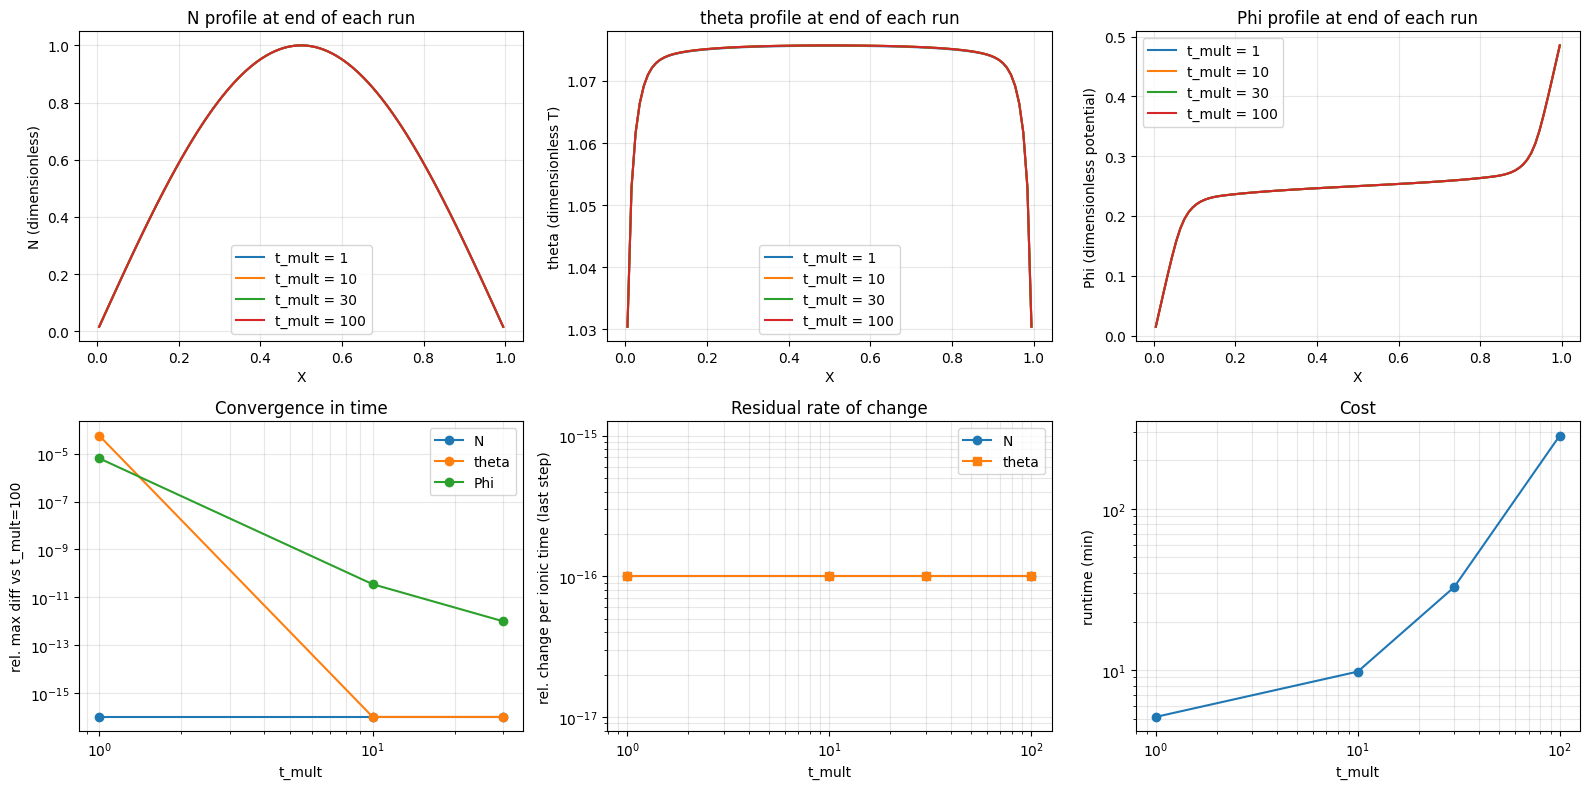

In [ ]:
import time
import numpy as np
import matplotlib.pyplot as plt

t_mult_list    = [1, 10, 30, 100]   
base_steps     = 1000               
steps_per_mult = 100                
save_files     = True              

def solve_electrical(N_val, theta_val, tol=1e-10, maxit=500):
    E = (-Phi.grad[0]).value.copy()
    w, prev = 0.3, np.inf

    for it in range(maxit):
        s = CellVariable(mesh=mesh, value=sigma_hat_of_N_theta_E(N_val, theta_val, E))
        Phi.setValue(X * Vapp / V_ref)
        DiffusionTerm(coeff=s.harmonicFaceValue, var=Phi).solve(var=Phi)
        E_new = (-Phi.grad[0]).value
        rel = np.linalg.norm(E_new - E) / (np.linalg.norm(E_new) + 1e-30)

        if rel < tol:
            break

        w = (max(0.7 * w, 0.01) if rel > prev else min(1.05 * w, 0.5))
        prev = rel
        E = (1 - w) * E + w * E_new
    return it + 1


def run_case(t_mult, n_time_steps):

    final_tau = t_mult / ion_ratio
    dtau = final_tau / n_time_steps

    print("\n" + "#" * 60)
    print(f"RUN: t_mult = {t_mult}")
    print(f"Requested time steps: {n_time_steps}")
    print(f"Time step dtau: {dtau:.4e}")
    print(f"Target dimensionless time: {final_tau:.4e}")
    print(f"Target physical time: {final_tau * t_ref:.4e} s")
    print("-" * 60, flush=True)

    Phi.setValue(X * Vapp / V_ref)
    theta.setValue(1.0)
    N.setValue(np.sin(np.pi * X))

    completed_steps = 0
    start_time = time.time()
    progress_every = max(1, n_time_steps // 10)

    for time_step in range(n_time_steps):

        N.updateOld()
        theta.updateOld()
        converged = False

        for sweep in range(max_sweeps):

            Phi_iter = CellVariable(name="Phi iteration", mesh=mesh, value=Phi.value.copy())
            theta_iter = CellVariable(name="theta iteration", mesh=mesh, value=theta.value.copy())
            N_iter = CellVariable(name="N iteration", mesh=mesh, value=N.value.copy())
            E_hat_value = (-Phi_iter.grad[0]).value
            D_hat_value = D_hat_of_theta(theta_iter.value)
            S_hat_value = S_hat_of_theta(theta_iter.value)
            v_hat_value = v_hat_of_theta_E(theta_iter.value, E_hat_value)
            D_hat = CellVariable(name="D_hat", mesh=mesh, rank=0, value=D_hat_value)
            S_hat = CellVariable(name="S_hat", mesh=mesh, rank=0, value=S_hat_value)
            solve_electrical(N_iter.value, theta_iter.value)

            E_hat_value = (-Phi.grad[0]).value
            v_hat_value = v_hat_of_theta_E(theta_iter.value, E_hat_value)
            E_hat_face = -Phi.faceGrad[0]
            theta_face = theta_iter.faceValue
            v_hat_face_value = v_hat_of_theta_E(theta_face.value, E_hat_face.value)
            D_face = D_hat_of_theta(theta_face.value)
            k_face = v_hat_face_value / D_face
            fl = np.asarray(mesh.facesLeft.value, dtype=bool)
            fr = np.asarray(mesh.facesRight.value, dtype=bool)
            coeff = np.array(v_hat_face_value, dtype=float, copy=True)
            coeff[fl] = (v_hat_face_value[fl] - D_face[fl] * k_face[fl]) / (1.0 + k_face[fl] * d)
            coeff[fr] = (v_hat_face_value[fr] - D_face[fr] * k_face[fr]) / (1.0 - k_face[fr] * d)
            v_hat = FaceVariable( name="v_hat", mesh=mesh, rank=1, value=(coeff,))
            diffusion_term = DiffusionTerm(coeff=D_hat, var=N)
            drift_term = PowerLawConvectionTerm(coeff=v_hat, var=N)
            soret_coeff_value = (D_hat_value * S_hat_value * N_iter.value)
            soret_cell = CellVariable(name="Soret coefficient (cell)", mesh=mesh, rank=0, value=soret_coeff_value)
            soret_coeff = FaceVariable(name="Soret coefficient", mesh=mesh, value=soret_cell.arithmeticFaceValue.value)
            soret_coeff.setValue(0., where=mesh.exteriorFaces)
            soret_term = DiffusionTerm(coeff=soret_coeff, var=theta)
            ambipolar_eq = (TransientTerm(var=N) == diffusion_term - drift_term + soret_term)
            ambipolar_eq.solve(var=N, dt=dtau)

            Jp_hat = (N.value * v_hat_value - D_hat_value * N.grad[0].value)
            sigma_hat_joule = sigma_hat_of_N_theta_E(N_iter.value, theta_iter.value, E_hat_value)
            heat_source_hat_value = (Gamma_el * sigma_hat_joule * E_hat_value**2)
            heat_source_hat = CellVariable(name="Dimensionless Joule Heating Source", mesh=mesh, rank=0, value=heat_source_hat_value)
            k_hat_value = k_hat_of_N_theta(N_iter.value, theta_iter.value)
            k_hat_value = np.maximum(k_hat_value, 1.0e-10)
            k_hat = CellVariable(name="k_hat", mesh=mesh, rank=0, value=k_hat_value)
            heat_eq = (TransientTerm(var=theta) == DiffusionTerm(coeff=alpha_ratio * k_hat, var=theta) + heat_source_hat)
            heat_eq.solve(var=theta, dt=dtau)

            Phi_change = np.max(np.abs(Phi.value - Phi_iter.value))
            theta_change = np.max(np.abs(theta.value - theta_iter.value))
            N_change = np.max(np.abs(N.value - N_iter.value))
            max_change = max(Phi_change, theta_change, N_change)

            del Phi_iter, theta_iter, N_iter

            if sweep == 0 or (sweep + 1) % 10 == 0:
                print(f"\rStep {time_step + 1}/{n_time_steps} | " f"Sweep {sweep + 1}/{max_sweeps} | " f"Coupling change = {max_change:.3e}", end="", flush=True)

            if max_change < coupling_tolerance:
                converged = True
                break

        if not converged:
            print(flush=True)
            print(f"WARNING: Coupling did not converge at " f"time step {time_step + 1}")
            print(f"Final coupling change = {max_change:.4e}")
            break

        completed_steps += 1

        if completed_steps == 1 or completed_steps % progress_every == 0:
            elapsed = time.time() - start_time
            est_remaining = elapsed / completed_steps * (n_time_steps - completed_steps)
            print(f"\nProgress: {completed_steps}/{n_time_steps} " f"({100 * completed_steps / n_time_steps:.1f}%) | " f"t = {completed_steps * dtau * t_ref:.4e} s | " f"elapsed {elapsed / 60:.2f} min | " f"remaining ~{est_remaining / 60:.2f} min", flush=True)

    elapsed_total = time.time() - start_time
    done = (completed_steps == n_time_steps)

    scale = dtau * ion_ratio
    rate_N     = np.max(np.abs(N.value - N.old.value)) / max(np.max(np.abs(N.value)), 1e-30) / scale
    rate_theta = np.max(np.abs(theta.value - theta.old.value)) / max(np.max(np.abs(theta.value)), 1e-30) / scale

    print("\n" + "=" * 60)
    print(f"SUMMARY  t_mult = {t_mult}")
    print(f"Completed steps    = {completed_steps}/{n_time_steps}")
    print(f"Actual physical t  = {completed_steps * dtau * t_ref:.4e} s")
    print(f"Runtime            = {elapsed_total / 60:.2f} min")
    print(f"Last-step rate N     = {rate_N:.3e}  (relative change per ionic time)")
    print(f"Last-step rate theta = {rate_theta:.3e}")
    print("Completed." if done else "WARNING: stopped before reaching target time.")
    print("=" * 60, flush=True)

    result = {"t_mult": t_mult, "n_steps": n_time_steps, "dtau": dtau, "completed": done, "t_phys": completed_steps * dtau * t_ref, "runtime_min": elapsed_total / 60, "rate_N": rate_N, "rate_theta": rate_theta, "N": N.value.copy(), "theta": theta.value.copy(), "Phi": Phi.value.copy(),}

    if save_files:
        np.savez(f"result_tmult_{t_mult:g}.npz",
                 N=result["N"], theta=result["theta"], Phi=result["Phi"],
                 t_phys=result["t_phys"], completed=done)
    return result

results = []
for tm in t_mult_list:
    n_steps = max(base_steps, int(round(steps_per_mult * tm)))
    results.append(run_case(tm, n_steps))

good = [r for r in results if r["completed"]]
if len(good) < 2:
    print("\nFewer than 2 completed runs, nothing to compare.")
else:
    ref = good[-1]
    print("\n" + "=" * 78)
    print(f"Relative max difference vs t_mult = {ref['t_mult']} (longest completed run)")
    print("=" * 78)
    print(f"{'t_mult':>8} {'t (s)':>12} {'steps':>7} {'N diff':>11} {'theta diff':>11} {'Phi diff':>11} {'min':>7}")
    for r in good:
        diffs = []
        for key in ["N", "theta", "Phi"]:
            diffs.append(np.max(np.abs(r[key] - ref[key])) / max(np.max(np.abs(ref[key])), 1e-30))
        print(f"{r['t_mult']:>8g} {r['t_phys']:>12.3e} {r['n_steps']:>7d} "
              f"{diffs[0]:>11.3e} {diffs[1]:>11.3e} {diffs[2]:>11.3e} {r['runtime_min']:>7.2f}")
        r["diffs"] = diffs

    print("\nSuccessive differences (run vs previous run):")
    for a, b in zip(good[:-1], good[1:]):
        out = []
        for key in ["N", "theta", "Phi"]:
            out.append(np.max(np.abs(b[key] - a[key])) / max(np.max(np.abs(b[key])), 1e-30))
        print(f"  t_mult {a['t_mult']:g} -> {b['t_mult']:g}: "
              f"N {out[0]:.3e} | theta {out[1]:.3e} | Phi {out[2]:.3e}")
    x = np.asarray(X.value if hasattr(X, "value") else X)

    fig, ax = plt.subplots(2, 3, figsize=(16, 8))
    for key, a, lab in [("N", ax[0, 0], "N (dimensionless)"),
                        ("theta", ax[0, 1], "theta (dimensionless T)"),
                        ("Phi", ax[0, 2], "Phi (dimensionless potential)")]:
        for r in good:
            a.plot(x, r[key], label=f"t_mult = {r['t_mult']:g}")
        a.set_xlabel("X"); a.set_ylabel(lab); a.legend(); a.grid(alpha=0.3)
        a.set_title(f"{key} profile at end of each run")

    tm_arr = np.array([r["t_mult"] for r in good[:-1]])
    for i, key in enumerate(["N", "theta", "Phi"]):
        vals = np.array([r["diffs"][i] for r in good[:-1]])
        ax[1, 0].loglog(tm_arr, np.maximum(vals, 1e-16), "o-", label=key)
    ax[1, 0].set_xlabel("t_mult"); ax[1, 0].set_ylabel(f"rel. max diff vs t_mult={ref['t_mult']}")
    ax[1, 0].set_title("Convergence in time"); ax[1, 0].legend(); ax[1, 0].grid(alpha=0.3, which="both")

    tm_all = np.array([r["t_mult"] for r in good])
    ax[1, 1].loglog(tm_all, [max(r["rate_N"], 1e-16) for r in good], "o-", label="N")
    ax[1, 1].loglog(tm_all, [max(r["rate_theta"], 1e-16) for r in good], "s-", label="theta")
    ax[1, 1].set_xlabel("t_mult"); ax[1, 1].set_ylabel("rel. change per ionic time (last step)")
    ax[1, 1].set_title("Residual rate of change"); ax[1, 1].legend(); ax[1, 1].grid(alpha=0.3, which="both")

    ax[1, 2].loglog(tm_all, [r["runtime_min"] for r in good], "o-")
    ax[1, 2].set_xlabel("t_mult"); ax[1, 2].set_ylabel("runtime (min)")
    ax[1, 2].set_title("Cost"); ax[1, 2].grid(alpha=0.3, which="both")
    plt.tight_layout()
    plt.savefig("tmult_convergence.png", dpi=150)
    plt.show()